# Effective Resolution Diagnostic Demo (ua, va)

This notebook demonstrates the **effective resolution metric** from Klaver et al. (2020), which objectively estimates the smallest spatial scale a climate model can plausibly represent.

## Why This Matters

Climate models have a **nominal resolution** (grid spacing) and an **effective resolution** (actual smallest resolved scale). The difference arises because:

- **Numerical diffusion** drains energy from small scales
- **Parameterizations** represent sub-grid processes
- **Anti-aliasing filters** prevent spectral artifacts
- **Interpolation** between grid points smooths fields

The effective resolution is typically **2.7-4.8× coarser** than the nominal grid spacing. This metric identifies where spectral energy begins to be artificially dissipated rather than representing atmospheric dynamics.

## Key Concepts

- **Nominal Resolution**: Grid spacing (e.g., 100 km)
- **Effective Resolution (L_eff)**: Actual smallest resolved scale (typically 2.7-4.8× coarser)
- **Detection Method**: Find where KE spectrum steepens beyond reference power law
- **2-of-3 Confirmation**: Requires at least 2 of 3 spectra (div_250, rot_250, rot_500) to steepen

## Method Overview

1. **Compute kinetic energy spectra** from spherical harmonic transforms of winds
2. **Fit spectral slopes** in sliding 20-wavenumber windows
3. **Detect steepening** where slope increases by ≥25% over a wavenumber doubling
4. **Apply 2-of-3 rule**: Require at least 2 of 3 spectra (divergent 250hPa, rotational 250hPa, rotational 500hPa) to steepen

## Reference

Klaver, R., Haarsma, R., Vidale, P. L., & Hazeleger, W. (2020). Effective resolution in high resolution global atmospheric models for climate studies. *Atmospheric Science Letters*, 21, e952. https://doi.org/10.1002/asl.952

## 1. Setup and Imports

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from pcmdi_metrics.effective_resolution import (
    compute_effective_resolution,
    process_effective_resolution,
)
from pcmdi_metrics.effective_resolution.lib import (
    EARTH_RADIUS,
    detect_steepening,
    plot_resolution_scatter,
    plot_spectra_and_slope,
    representative_grid_box_distance,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

## 2. Generate Synthetic Data

To demonstrate the diagnostic, we'll create synthetic wind data with **prescribed kinetic energy spectra** that roll off at specific wavenumbers.

### How the Synthetic Data Works

1. **Define target spectra** with exponential roll-off at chosen wavenumbers (l=50, 70, 62 for div, rot@250, rot@500)
2. **Generate random spherical harmonic coefficients** with power matching the target spectrum
3. **Inverse transform** to create realistic wind fields (u, v) on a regular lat-lon grid
4. **Normalize** to have realistic wind speeds (~25 m/s RMS)

This allows us to test the diagnostic with **known** effective resolutions and verify it correctly identifies the spectral steepening.

### Key Parameters

- `rolloff=(50, 70, 62)`: Wavenumbers where each spectrum steepens (div_250, rot_250, rot_500)
- `decay=40`: Controls how sharply the spectrum drops beyond rolloff
- Grid: 192×384 (roughly 1° resolution), 8 timesteps, 2 pressure levels (250, 500 hPa)

In [2]:
from pcmdi_metrics.effective_resolution.lib.ke_spectra import _legendre


def random_coefficients(target_spectrum, rng, rsphere=EARTH_RADIUS):
    """Random vorticity/divergence coefficients whose power follows `target_spectrum`."""
    ell = np.arange(target_spectrum.size, dtype=float)
    ntrunc = ell.size - 1
    with np.errstate(divide="ignore", invalid="ignore"):
        variance = 2.0 * target_spectrum * ell * (ell + 1.0) / (rsphere**2 * (2 * ell + 1.0))
    variance[0] = 0.0

    coeffs = np.zeros((ntrunc + 1, ntrunc + 1), dtype=complex)
    coeffs[:, 0] = np.sqrt(variance) * rng.normal(size=ntrunc + 1)  # m = 0 must be real
    for m in range(1, ntrunc + 1):
        scale = np.sqrt(variance[m:] / 2.0)
        size = ntrunc + 1 - m
        coeffs[m:, m] = scale * (rng.normal(size=size) + 1j * rng.normal(size=size))
    return coeffs


def synthesize_wind(ke_rot, ke_div, lat, nlon, rng, rsphere=EARTH_RADIUS):
    """Inverse spherical-harmonic transform: (u, v) with the requested KE spectra."""
    ell = np.arange(ke_rot.size, dtype=float)
    ntrunc = ell.size - 1
    with np.errstate(divide="ignore", invalid="ignore"):
        to_potential = np.where(ell > 0, -(rsphere**2) / (ell * (ell + 1.0)), 0.0)[:, None]
    psi = to_potential * random_coefficients(ke_rot, rng)   # streamfunction
    chi = to_potential * random_coefficients(ke_div, rng)   # velocity potential

    mu = np.sin(np.deg2rad(lat))
    cosphi = np.cos(np.deg2rad(lat))
    u_f = np.zeros((lat.size, nlon // 2 + 1), dtype=complex)
    v_f = np.zeros_like(u_f)
    for m in range(ntrunc + 1):
        p, h = _legendre(m, ntrunc, mu)
        u_f[:, m] = (1j * m * (chi[m:, m][:, None] * p).sum(0)
                     - (psi[m:, m][:, None] * h).sum(0)) / rsphere
        v_f[:, m] = (1j * m * (psi[m:, m][:, None] * p).sum(0)
                     + (chi[m:, m][:, None] * h).sum(0)) / rsphere
    u = np.fft.irfft(u_f, n=nlon, axis=1) * nlon / cosphi[:, None]
    v = np.fft.irfft(v_f, n=nlon, axis=1) * nlon / cosphi[:, None]
    return u, v

### Create Dummy Dataset

This synthetic model has a 192×384 grid (roughly 1° resolution) with spectra that steepen around l~50-60.

In [3]:
def make_dummy_dataset(nlat=192, nlon=384, ntime=8, seed=0,
                       rolloff=(50.0, 70.0, 62.0), rms_wind=25.0, decay=40.0):
    """A CMIP-like (time, plev, lat, lon) wind Dataset with a prescribed KE spectrum.

    `rolloff` gives the cut-off wavenumber of the divergent spectrum, the rotational
    spectrum at 250 hPa, and the rotational spectrum at 500 hPa.
    """
    rng = np.random.default_rng(seed)
    lat = np.linspace(-90.0 + 90.0 / nlat, 90.0 - 90.0 / nlat, nlat)
    lon = np.arange(0.0, 360.0, 360.0 / nlon)

    ell = np.arange(nlat, dtype=float)
    with np.errstate(divide="ignore"):
        power_law = np.where(ell > 0, ell**-3.0, 0.0)

    def shaped(cut):
        return power_law * np.exp(-np.maximum(ell - cut, 0.0) / decay)

    div_cut, rot250_cut, rot500_cut = rolloff
    per_level = {
        250.0: (shaped(rot250_cut), 0.05 * shaped(div_cut)),
        500.0: (shaped(rot500_cut), 0.05 * shaped(div_cut)),
    }

    u = np.empty((ntime, 2, nlat, nlon))
    v = np.empty_like(u)
    for it in range(ntime):
        for ip, level in enumerate((250.0, 500.0)):
            ke_rot, ke_div = per_level[level]
            u_t, v_t = synthesize_wind(ke_rot, ke_div, lat, nlon, rng)
            norm = rms_wind / np.sqrt((u_t**2 + v_t**2).mean())
            u[it, ip], v[it, ip] = u_t * norm, v_t * norm

    # Use proper datetime coordinates (required for temporal_averaging='slopes')
    import pandas as pd
    time_coords = pd.date_range('2014-03-01', periods=ntime, freq='6h')
    
    ds = xr.Dataset(
        {"ua": (("time", "plev", "lat", "lon"), u),
         "va": (("time", "plev", "lat", "lon"), v)},
        coords={"time": ("time", time_coords),
                "plev": ("plev", np.array([25000.0, 50000.0])),
                "lat": ("lat", lat),
                "lon": ("lon", lon)},
    )
    ds["plev"].attrs.update(units="Pa", axis="Z", standard_name="air_pressure")
    ds["lat"].attrs.update(units="degrees_north", axis="Y", standard_name="latitude")
    ds["lon"].attrs.update(units="degrees_east", axis="X", standard_name="longitude")
    ds["time"].attrs.update(axis="T", standard_name="time")
    ds["ua"].attrs.update(units="m s-1", long_name="Eastward wind")
    ds["va"].attrs.update(units="m s-1", long_name="Northward wind")
    return ds


ds = make_dummy_dataset()
ds

<xarray.Dataset> Size: 19MB
Dimensions:  (time: 8, plev: 2, lat: 192, lon: 384)
Coordinates:
  * time     (time) datetime64[us] 64B 2014-03-01 ... 2014-03-02T18:00:00
  * plev     (plev) float64 16B 2.5e+04 5e+04
  * lat      (lat) float64 2kB -89.53 -88.59 -87.66 -86.72 ... 87.66 88.59 89.53
  * lon      (lon) float64 3kB 0.0 0.9375 1.875 2.812 ... 357.2 358.1 359.1
Data variables:
    ua       (time, plev, lat, lon) float64 9MB 8.062 7.951 ... -0.8033 -1.038
    va       (time, plev, lat, lon) float64 9MB 6.775 6.901 ... -14.28 -14.27

### Inspect the Data

Before computing effective resolution, let's examine:

1. **Grid box distance (L̃_box)**: The area-weighted mean diagonal distance between grid points
   - This represents the model's **nominal resolution**
   - For this 192×384 grid, L̃_box ≈ 134 km
   
2. **Wind field visualization**: Shows the synthetic atmospheric flow pattern
   - Notice the realistic spatial structure from inverse spherical harmonic transform
   - Contains scales from planetary waves down to grid scale

representative grid box distance L_box = 134.0 km


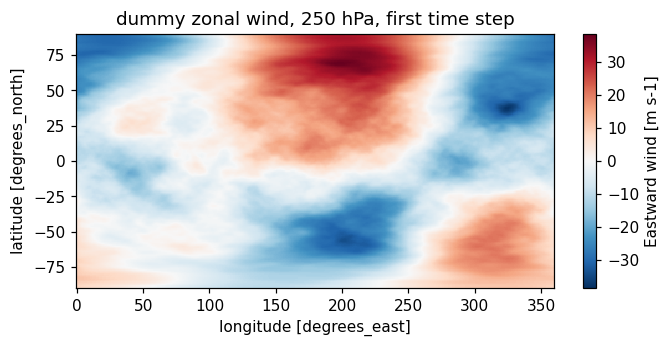

In [4]:
lbox = representative_grid_box_distance(ds["lat"].values, ds["lon"].values)
print(f"representative grid box distance L_box = {lbox:.1f} km")

fig, ax = plt.subplots(figsize=(7, 3))
mesh = ds["ua"].isel(time=0, plev=0).plot(ax=ax, cmap="RdBu_r", add_colorbar=True)
ax.set_title("dummy zonal wind, 250 hPa, first time step")
plt.show()

## 3. Compute Effective Resolution

The main API function `compute_effective_resolution()` performs the complete diagnostic:

### Processing Steps

1. **Spherical harmonic transform** → vorticity and divergence coefficients (exact, no finite differences)
2. **Kinetic energy spectra** → E(l) for rotational and divergent components at each pressure level
3. **Temporal averaging** → combine spectra across timesteps (by default: compute monthly slopes → average)
4. **Spectral slope fitting** → fit E ∝ l^(-n) in sliding 20-wavenumber windows to get n(l)
5. **Steepening detection** → find smallest l where n increases by ≥25% over wavenumber doubling
6. **2-of-3 confirmation** → require at least 2 of 3 spectra (div_250, rot_250, rot_500) to steepen
7. **Effective resolution** → median of detected wavenumbers → convert to length scale

### Why This Approach Works

- **Spherical harmonics** preserve high-wavenumber information (unlike finite differences)
- **Slope fitting** smooths out noise while capturing spectral behavior
- **Steepening criterion** identifies transition from resolved to numerically dissipated scales
- **2-of-3 rule** provides robustness against spurious detections in individual spectra

In [5]:
metrics, diagnostics = compute_effective_resolution(
    ds,
    uvar="ua",
    vvar="va",
    levels=(250.0, 500.0),
    model="DUMMY-HR",
    member="r1i1p1f1",
)

result = metrics["DUMMY-HR"]["r1i1p1f1"]
result

{'effective_wavenumber': 63.0,
 'effective_resolution_km': 315.2079888788274,
 'grid_box_distance_km': 133.99631291692674,
 'resolution_ratio': 2.352363151023759,
 'resolution_ratio_dx_convention': 6.653487743609018,
 'is_upper_limit': False,
 'criterion': {'fit_window': 20,
  'fit_anchor': 'right',
  'steepening_factor': 0.25,
  'wavenumber_ratio': 2.0,
  'min_wavenumber': 32,
  'n_confirm': 2},
 'reference': 'Klaver et al. (2020), doi:10.1002/asl.952',
 'n_spectra_steepening': 3,
 'steepening_wavenumber': {'div_250': 51.0, 'rot_250': 70.0, 'rot_500': 63.0},
 'steepening_eddy_scale_km': {'div_250': 388.6607799933854,
  'rot_250': 283.9090806701491,
  'rot_500': 315.2079888788274},
 'steepening_wavenumber_range': [51.0, 70.0]}

In [6]:
import pandas as pd

summary = pd.Series(
    {
        "effective wavenumber l_eff": result["effective_wavenumber"],
        "effective resolution L_eff (km)": round(result["effective_resolution_km"], 1),
        "grid box distance L_box (km)": round(result["grid_box_distance_km"], 1),
        "ratio L_eff / L_box": round(result["resolution_ratio"], 2),
        "ratio in the dx convention": round(result["resolution_ratio_dx_convention"], 2),
        "spectra showing steepening": f"{result['n_spectra_steepening']} of 3",
        "upper limit only": result["is_upper_limit"],
    },
    name="value",
)
print(summary.to_string())
print()
print("per-spectrum detections (wavenumber -> eddy scale):")
for key, wavenumber in result["steepening_wavenumber"].items():
    scale = result["steepening_eddy_scale_km"][key]
    print(f"  {key:8s}  l = {wavenumber}   ΔS = {scale:.0f} km")

effective wavenumber l_eff           63.0
effective resolution L_eff (km)     315.2
grid box distance L_box (km)        134.0
ratio L_eff / L_box                  2.35
ratio in the dx convention           6.65
spectra showing steepening         3 of 3
upper limit only                    False

per-spectrum detections (wavenumber -> eddy scale):
  div_250   l = 51.0   ΔS = 389 km
  rot_250   l = 70.0   ΔS = 284 km
  rot_500   l = 63.0   ΔS = 315 km


### Results Summary

The diagnostic returns comprehensive metrics:

#### Core Metrics
- **l_eff = 63**: Effective wavenumber where spectrum steepens (median of 51, 70, 63)
- **L_eff = 315 km**: Effective resolution = smallest plausibly resolved eddy scale
- **L̃_box = 134 km**: Nominal grid box distance

#### Resolution Ratio
- **L_eff / L̃_box = 2.35**: The model resolves scales **2.35× larger** than its grid spacing
  - For real climate models, this ratio ranges from **2.7 to 4.8**
  - Lower ratio = model resolves closer to grid scale (more effective)
  - Higher ratio = more energy lost to numerical dissipation

#### Per-Spectrum Detections
Shows where each component steepens:
- **div_250**: l=51 → 389 km (divergent flow at 250 hPa steepens earliest)
- **rot_250**: l=70 → 284 km (rotational flow at 250 hPa)
- **rot_500**: l=63 → 315 km (rotational flow at 500 hPa)

The **median (l=63)** becomes the effective resolution since 3 of 3 spectra steepen (exceeds 2-of-3 threshold).

#### Physical Interpretation
Atmospheric features **smaller than L_eff = 315 km** in this model are dominated by numerical effects rather than resolved dynamics. Metrics computed at finer scales measure the numerical scheme, not the climate.

## 4. Visualize Spectra and Slope Detection

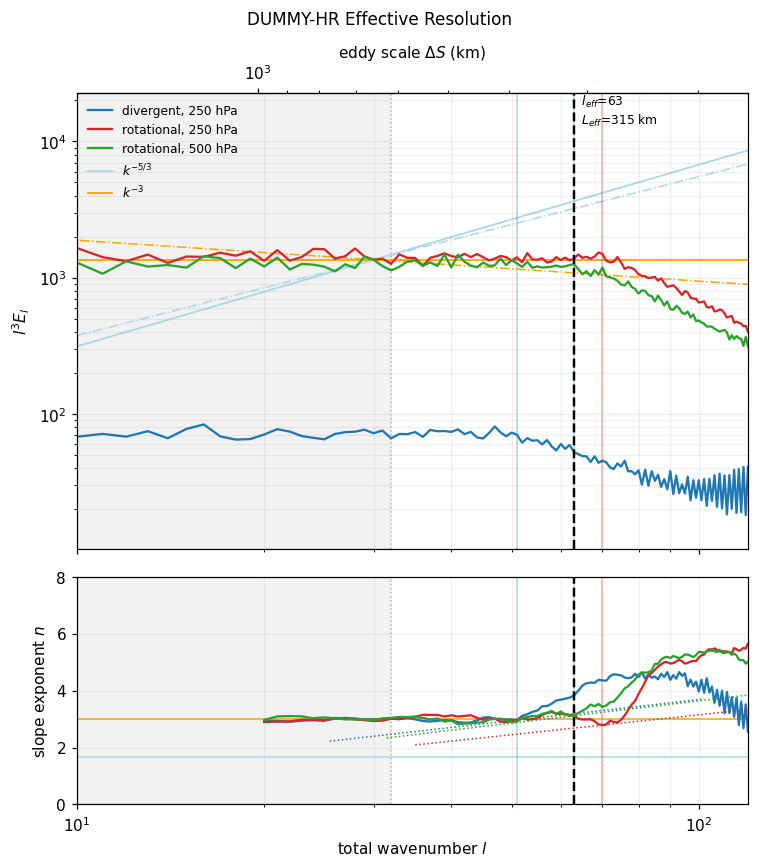

In [7]:
fig = plot_spectra_and_slope(
    diagnostics,
    result,
    xlim=(10, 120),
    title="DUMMY-HR Effective Resolution"
)
plt.show()

### Understanding the Visualization

This reproduces **Figure 1** from Klaver et al. (2020) with two key panels:

#### Top Panel: Compensated Kinetic Energy Spectra (l³E_l)
- Shows deviation from the **theoretical k⁻³ power law** for atmospheric turbulence
- **Flat plateau** = spectrum follows k⁻³ (resolved scales)
- **Downward curve** = spectrum steepens beyond k⁻³ (numerical dissipation)
- Three lines for divergent@250, rotational@250, rotational@500
- **Compensating by l³** makes deviations from power law visually obvious

#### Bottom Panel: Spectral Slope Exponent n(l)
- Shows fitted exponent where E ∝ l^(-n) locally
- **Horizontal at n≈3** = following k⁻³ power law (resolved)
- **Increasing n** = spectrum steepening (transition to unresolved)
- **Critical curve (blue)** = 25% steepening criterion
- **Vertical dashed lines** = detected steepening wavenumbers (where slope crosses threshold)

#### What to Look For
- Divergent spectrum (div_250) steepens **earliest** (l=51) → most sensitive indicator
- Rotational spectra steepen later → represent large-scale balanced flow better
- Effective resolution = **median** of the three detections → robust against outliers
- Steepening = transition from atmospheric dynamics to numerical artifact

## 5. Advanced Usage

### Temporal Averaging Strategies

The implementation offers two approaches for combining spectra across time, following different interpretations of Klaver et al. (2020):

#### Method 1: `temporal_averaging='slopes'` (Default)
Matches **Appendix S3** of the reference paper:
1. Compute KE spectrum for each month separately
2. Fit spectral slopes to each monthly spectrum → n_month(l)
3. Average slope curves across months → n̄(l)
4. Detect steepening from averaged slopes

**Advantage**: Preserves information about temporal variability in spectral shape before averaging

#### Method 2: `temporal_averaging='spectra'` (Alternative)
Original implementation approach:
1. Average KE spectra first across all timesteps → Ē(l)
2. Fit slopes to the time-averaged spectrum → n(l)
3. Detect steepening from this single slope curve

**Advantage**: Simpler, reduces to one spectrum per component

#### When They Differ
For **temporally stable** spectra (like this synthetic example), both methods give identical results. Differences emerge when:
- Seasonal cycles affect spectral shape
- Different atmospheric regimes are present
- Limited temporal sampling creates noise

For real climate data with seasonal variations, `temporal_averaging='slopes'` is recommended as it better represents the paper's methodology.

In [8]:
# Method 1: Average slopes (default, matches Klaver et al. Appendix S3)
metrics_slopes, _ = compute_effective_resolution(
    ds,
    temporal_averaging='slopes',  # Compute monthly spectra → fit monthly slopes → average slopes
    model="DUMMY-HR",
    member="r1i1p1f1"
)

# Method 2: Average spectra (original implementation)
metrics_spectra, _ = compute_effective_resolution(
    ds,
    temporal_averaging='spectra',  # Average spectra first → fit single slope curve
    model="DUMMY-HR",
    member="r1i1p1f1"
)

print("Temporal averaging comparison:")
print(f"  slopes method:  l={metrics_slopes['DUMMY-HR']['r1i1p1f1']['effective_wavenumber']}")
print(f"  spectra method: l={metrics_spectra['DUMMY-HR']['r1i1p1f1']['effective_wavenumber']}")
print("\nNote: Results are often identical for temporally stable spectra")

Temporal averaging comparison:
  slopes method:  l=63.0
  spectra method: l=63.0

Note: Results are often identical for temporally stable spectra


### Parameter Sensitivity

Several parameters control the detection behavior. Understanding their effects helps tune the diagnostic for specific applications:

#### `steepening_factor` (default: 0.25)
**Controls stringency of steepening detection**
- Criterion: slope must increase by this fraction over wavenumber doubling
- **Higher values** (e.g., 0.30) → more stringent → detects later → **coarser** effective resolution
- **Lower values** (e.g., 0.20) → less stringent → detects earlier → **finer** effective resolution
- Paper uses 0.25 (25% increase) but notes it's "somewhat arbitrary"
- **When to adjust**: If detection seems too sensitive/insensitive to spectral features

#### `min_wavenumber` (default: 32)
**Excludes low wavenumbers from detection**
- Prevents detection in planetary-scale range where spectral behavior may be irregular
- **Higher values** (e.g., 50) → start looking later → may miss early steepening
- **Lower values** (e.g., 20) → include more planetary scales → risk false detections
- **When to adjust**: For coarse-resolution models where steepening occurs at low wavenumbers

#### Other Useful Parameters
- `fit_window` (default: 20): Window size for slope fitting
  - Larger = smoother slopes, less sensitive to noise
  - Smaller = captures finer spectral features, more noise-sensitive
  
- `fit_anchor` (default: 'right'): Where to assign fitted slope within window
  - 'right' = assign to highest wavenumber (literal paper reading)
  - 'center' = assign to window midpoint (conventional)
  - 'left' = assign to lowest wavenumber
  
- `ntrunc`: Triangular truncation limit (default: nlat-1)
  - Useful for matching specific truncation used in spectral models

**Note**: In this synthetic example, results are insensitive to these parameters because the prescribed rolloff creates very clear, stable steepening signals.

In [9]:
# steepening_factor: threshold for detecting steepening (default 0.25 = 25%)
# Higher values → more stringent → later detection → coarser effective resolution
metrics_025, _ = compute_effective_resolution(ds, steepening_factor=0.25, model="test", member="r1i1p1f1")
metrics_030, _ = compute_effective_resolution(ds, steepening_factor=0.30, model="test", member="r1i1p1f1")

print("Steepening factor sensitivity:")
print(f"  factor=0.25: L_eff={metrics_025['test']['r1i1p1f1']['effective_resolution_km']:.1f} km")
print(f"  factor=0.30: L_eff={metrics_030['test']['r1i1p1f1']['effective_resolution_km']:.1f} km")

# min_wavenumber: exclude low wavenumbers from detection (default 32)
# Higher values → start detection later → may find coarser resolution
metrics_min32, _ = compute_effective_resolution(ds, min_wavenumber=32, model="test", member="r1i1p1f1")
metrics_min50, _ = compute_effective_resolution(ds, min_wavenumber=50, model="test", member="r1i1p1f1")

print("\nMinimum wavenumber restriction:")
print(f"  min_l=32 (default): l_eff={metrics_min32['test']['r1i1p1f1']['effective_wavenumber']}")
print(f"  min_l=50:           l_eff={metrics_min50['test']['r1i1p1f1']['effective_wavenumber']}")

Steepening factor sensitivity:
  factor=0.25: L_eff=315.2 km
  factor=0.30: L_eff=315.2 km

Minimum wavenumber restriction:
  min_l=32 (default): l_eff=63.0
  min_l=50:           l_eff=63.0


## 6. Important Notes and Caveats

### Critical Data Requirements

**It is recommended to use **NATIVE GRID data** (`grid_label='gn'` in CMIP6) for this diagnostics:

❌ **Do NOT use**:
- Regridded data (`grid_label='gr'`) → destroys high-wavenumber information
- Daily mean winds → temporal smoothing removes small-scale transients
- Coarse vertical resolution → limited to 250 and 500 hPa in standard implementation
- Data on interpolated grids → introduces artificial spectral characteristics

✅ **Required**:
- 6-hourly (or finer) instantaneous winds on model's native horizontal grid
- Global coverage (method assumes spherical harmonic basis)
- Variables: `ua`, `va` at 250 and 500 hPa
- Pressure coordinates can be in Pa or hPa (auto-detected)

### Physical Interpretation

**What L_eff tells you**:
- Features **smaller than L_eff** are dominated by numerical dissipation, not resolved dynamics
- Metrics evaluated at scales < L_eff measure the numerical scheme, not the climate
- L_eff sets a **lower bound** for meaningful process studies in the model

**What L_eff does NOT tell you**:
- Nothing about **fidelity** of scales larger than L_eff (a model can have good L_eff but poor large-scale spectrum)
- Nothing about **vertical** resolution (diagnostic is horizontal-only)
- Nothing about temporal resolution or transient representation

### Known Limitations

1. **Global time-mean approach**: 
   - May mask phenomenon-dependent resolution (tropical convection vs. extratropical storms)
   - Single value doesn't capture regional or seasonal variations
   
2. **Ad hoc threshold**: 
   - 25% steepening criterion is "somewhat arbitrary" (authors' words)
   - Different thresholds shift detected wavenumber by ~10-20%
   
3. **Vertical sparsity**: 
   - Only 2 levels tested (250, 500 hPa)
   - Focuses on troposphere; may not represent stratosphere or boundary layer
   
4. **Divergent spectrum exclusion at 500 hPa**:
   - Paper finds div_500 steepens at all scales → provides no useful signal
   - Excluded from 2-of-3 confirmation rule

### Comparison with Reference Paper

This implementation uses **strict algorithmic detection** of the 25% criterion. The reference paper (Klaver et al. 2020 Table 1) used **visual inspection with expert interpretation** of "broader spectral behavior."

**Expected differences**: Results may differ by **10-30%** from Table 1 values, which is acceptable given the methodological difference:
- **Reference approach**: Visual assessment + physical interpretation → not reproducible
- **This implementation**: Objective algorithm → reproducible for model intercomparison

**Recommendation**: Use results to **compare models** relative to each other, not to expect exact Table 1 reproduction.

### Further Information

- Full methodology: See README.md and Klaver et al. (2020) paper
- Investigation of discrepancies: See `tests/DISCREPANCY_ANALYSIS.md`
- Real model examples: See test notebooks in `tests/` directory

## 7. Advanced: Direct KE Spectra Analysis

For advanced users who want just the kinetic energy spectra without running the full effective resolution diagnostic, you can use the standalone spectral functions:

- `compute_ke_spectra()`: Single snapshot (2D u/v fields)
- `compute_ke_spectra_timeseries()`: Time loop + averaging (3D/4D fields)

These are the same functions used internally by `compute_effective_resolution()`, now available as public APIs.


In [10]:
from pcmdi_metrics.effective_resolution import (
    compute_ke_spectra,
    compute_ke_spectra_timeseries,
)

# Example 1: Single snapshot (time AND level already selected)
print("Example 1: Single Snapshot KE Spectrum")
print("=" * 50)
# Must select BOTH time and pressure level for 2D field
ds_snapshot = ds.sel(plev=25000).isel(time=0)  # Select 250 hPa and one timestep
ke_single = compute_ke_spectra(ds_snapshot, uvar='ua', vvar='va')

print(f"Output variables: {list(ke_single.data_vars)}")
print(f"Wavenumber range: {int(ke_single.wavenumber.min())} to {int(ke_single.wavenumber.max())}")
print(f"Rotational KE range: {ke_single.ke_rot.min().values:.2e} to {ke_single.ke_rot.max().values:.2e} m²/s²")
print()

# Example 2: Time-averaged spectrum (RECOMMENDED for diagnostics)
print("Example 2: Time-Averaged KE Spectrum")
print("=" * 50)
# compute_ke_spectra_timeseries handles level selection AND time loop automatically
ke_averaged = compute_ke_spectra_timeseries(
    ds,
    uvar='ua',
    vvar='va',
    level_hpa=250.0,  # Specify level in hPa
    time_mean=True    # Average spectra (not fields!) - scientifically correct
)

print(f"Averaged over: {ke_averaged.attrs.get('n_times_averaged', 'N/A')} timesteps")
print(f"Output variables: {list(ke_averaged.data_vars)}")
print(f"✓ Used correct time averaging methodology")
print()

# Example 3: Keep time dimension for temporal analysis
print("Example 3: KE Spectrum Time Evolution")
print("=" * 50)
ke_timeseries = compute_ke_spectra_timeseries(
    ds,
    uvar='ua',
    vvar='va',
    level_hpa=250.0,
    time_mean=False  # Keep time dimension
)

print(f"Shape: (time={ke_timeseries.sizes['time']}, wavenumber={ke_timeseries.sizes['wavenumber']})")
print(f"Can now analyze temporal variability of spectra!")


Example 1: Single Snapshot KE Spectrum
Output variables: ['ke_rot', 'ke_div', 'ke_total']
Wavenumber range: 1 to 191
Rotational KE range: 3.20e-05 to 7.26e+02 m²/s²

Example 2: Time-Averaged KE Spectrum
Averaged over: 8 timesteps
Output variables: ['ke_rot', 'ke_div', 'ke_total']
✓ Used correct time averaging methodology

Example 3: KE Spectrum Time Evolution
Shape: (time=8, wavenumber=191)
Can now analyze temporal variability of spectra!


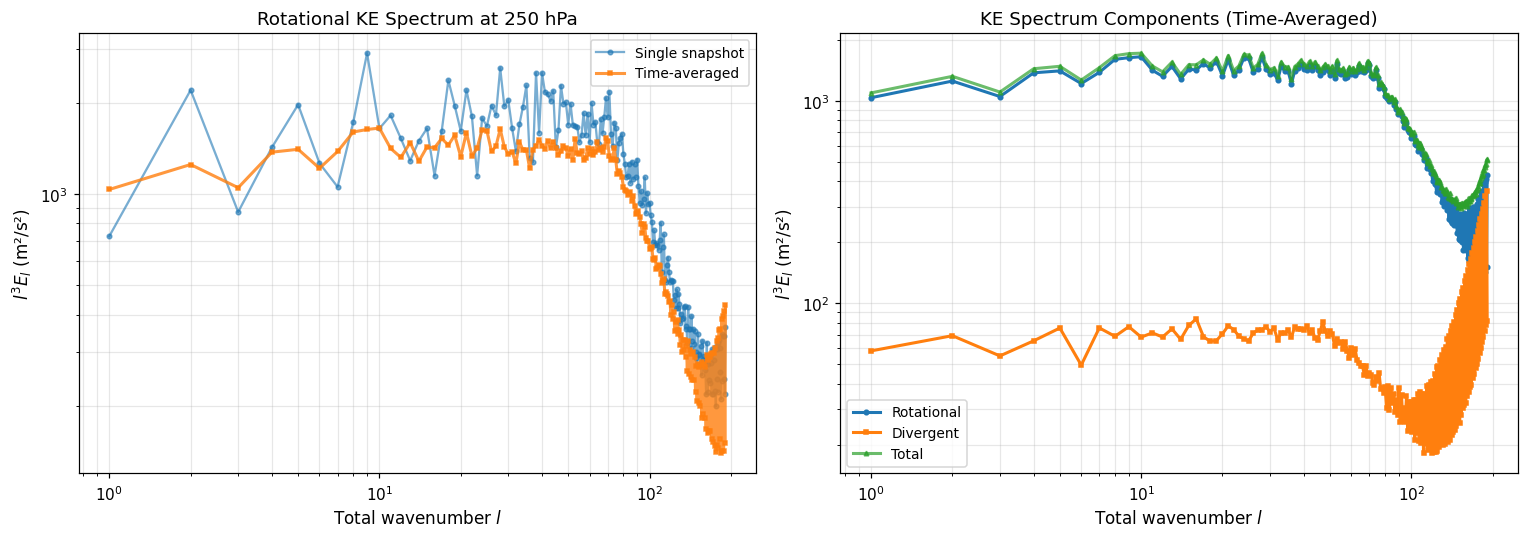


✓ Direct KE spectral analysis complete!

When to use each function:
  • compute_ke_spectra()           → Single snapshot already selected
  • compute_ke_spectra_timeseries() → Time-varying data (handles averaging)
  • compute_effective_resolution()  → Full diagnostic with L_eff metric


In [11]:
import matplotlib.pyplot as plt

# Visualize the spectra
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Compare single snapshot vs time-averaged
ell = ke_single.wavenumber.values
ax1.loglog(ell, ell**3 * ke_single.ke_rot, 'o-', alpha=0.6, 
           label='Single snapshot', markersize=3)
ax1.loglog(ell, ell**3 * ke_averaged.ke_rot, 's-', alpha=0.8,
           label='Time-averaged', markersize=3, linewidth=2)
ax1.set_xlabel('Total wavenumber $l$', fontsize=11)
ax1.set_ylabel('$l^3 E_l$ (m²/s²)', fontsize=11)
ax1.set_title('Rotational KE Spectrum at 250 hPa', fontsize=12)
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3, which='both')

# Right: Rotational vs Divergent
ax2.loglog(ell, ell**3 * ke_averaged.ke_rot, 'o-', 
           label='Rotational', markersize=3, linewidth=2)
ax2.loglog(ell, ell**3 * ke_averaged.ke_div, 's-',
           label='Divergent', markersize=3, linewidth=2)
ax2.loglog(ell, ell**3 * ke_averaged.ke_total, '^-',
           label='Total', markersize=3, linewidth=2, alpha=0.7)
ax2.set_xlabel('Total wavenumber $l$', fontsize=11)
ax2.set_ylabel('$l^3 E_l$ (m²/s²)', fontsize=11)
ax2.set_title('KE Spectrum Components (Time-Averaged)', fontsize=12)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("✓ Direct KE spectral analysis complete!")
print("="*70)
print("\nWhen to use each function:")
print("  • compute_ke_spectra()           → Single snapshot already selected")
print("  • compute_ke_spectra_timeseries() → Time-varying data (handles averaging)")
print("  • compute_effective_resolution()  → Full diagnostic with L_eff metric")
